# Ejercicio 2: aprendizaje de una pauta TWAP

**Bloques nuevos:** referencia determinista, recompensa temporal, experimentos y gráficos. El agente DDQN reutiliza el ejercicio 1; se ha retirado la compra forzada del primer paso. Se utilizan datos de entrenamiento de REP. Las comparaciones no prueban generalización fuera de muestra.

El estado contiene las fracciones de tiempo y volumen restantes. Su diferencia es la desviación entre el volumen ejecutado y el tiempo transcurrido. La acción 0 espera y la 1 compra un título. La referencia ejecuta $\lfloor Vt/H\rfloor$ títulos tras el paso $t$.


In [1]:
import pickle, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from src.agents.dqn import DDQNAgent
from src.agents.twap import twap_action
from src.environment.best_execution import BestExecutionEnv
from src.environment.config import EnvironmentConfig
from src.rewards import TwapRewardStrategy, VwapRewardStrategy

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'setup.py').exists())
with (root / 'data/rep_data.pkl').open('rb') as f:
    data = pickle.load(f)['train']
excluded_days = [day for day, frame in data.items() if (frame.cumvol.diff() < 0).any()]
print('Días excluidos por descenso de cumvol:', excluded_days)
data = {day: frame for day, frame in data.items() if day not in excluded_days}
print('Días de entrenamiento utilizados:', len(data))


Días excluidos por descenso de cumvol: [datetime.date(2018, 2, 12), datetime.date(2018, 3, 1)]
Días de entrenamiento utilizados: 58


## Recompensa y entrenamiento

La recompensa es $-|q_t/V-t/H|$ o su cuadrado negativo. Se penaliza la fracción pendiente al finalizar. Si se completa antes del horizonte se suma el error de los pasos restantes con el mismo descuento del agente, evitando que finalizar pronto oculte ese error. Esto utiliza la trayectoria temporal, no precios futuros.

El buffer conserva 2.000 transiciones, con batch 32 y calentamiento de 256. Adam usa 0,001, dos capas de 32 neuronas, aprendizaje cada 16 pasos y copia objetivo cada 128. Epsilon baja linealmente de 1 a 0,05 durante las interacciones; la exploración adaptativa corresponde al ejercicio 3. Los valores son un punto de partida; la comparación posterior evalúa recompensa y gamma por separado.


In [2]:
STEPS = 100_000
SEEDS = (11, 23, 42)

def make_reward(kind, gamma):
    if kind == 'vwap':
        return VwapRewardStrategy()
    return TwapRewardStrategy(gamma=gamma, power=1 if kind == 'absolute' else 2)

def train(kind, gamma, seed):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    env = BestExecutionEnv(data, EnvironmentConfig(seed=seed), make_reward(kind, gamma))
    agent = DDQNAgent(env, gamma=gamma, epsilon=1., alpha=.001, batch_size=32,
                      buffer_size=2000, hidden_neurons=32)
    s = env.reset()
    for _ in range(256):
        a = env.action_sample()
        s1, r, done, _ = env.step(a)
        agent.experience(s, a, r, s1, done)
        s = env.reset() if done else s1
    records, total, episode_steps = [], 0., 0
    s = env.reset()
    started = time.monotonic()
    for step in range(1, STEPS + 1):
        a = agent.act(s)
        s1, r, done, _ = env.step(a)
        agent.experience(s, a, r, s1, done)
        total += r
        episode_steps += 1
        if step % 16 == 0:
            agent.learn()
        if step % 128 == 0:
            agent.update_target()
        agent.epsilon = max(.05, 1 - .95 * step / STEPS)
        if done:
            records.append((step, total, episode_steps))
            s, total, episode_steps = env.reset(), 0., 0
        else:
            s = s1
    agent.set_trainable(False)
    print(kind, gamma, seed, 'segundos', round(time.monotonic()-started, 1), flush=True)
    return agent, pd.DataFrame(records, columns=['step', 'reward', 'episode_steps'])


## Episodios de comparación

Se excluyen los días cuyo volumen acumulado disminuye, ya que el entorno los rechaza. Se fijan tres días y tres posiciones de inicio, cruzados con tres duraciones y tres proporciones de orden. Cada ventana tiene exactamente la longitud necesaria, de modo que todas las políticas recorren las mismas filas. La evaluación usa `train` y no constituye una prueba fuera de muestra.


In [3]:
days = list(data)
cases = []
for horizon in (400, 500, 600):
    for fraction in (.075, .10, .125):
        volume = int(horizon * fraction)
        for day_index, position_fraction in ((0, .1), (len(days)//2, .5), (-1, .9)):
            day = days[day_index]
            frame = data[day]
            start = 60 + int((len(frame) - horizon - 60) * position_fraction)
            window = frame.iloc[start-60:start+horizon].copy()
            cases.append((day, start, horizon, volume, window))
assert len(cases) == 27

def evaluate(policy, case):
    day, start, horizon, volume, window = case
    # nextafter evita perder una unidad por redondeo en int(fracción * horizonte).
    fraction = np.nextafter(volume / horizon, 1.)
    cfg = EnvironmentConfig(look_back=60, min_episode_bins=horizon, max_episode_bins=horizon,
                            min_care_fraction=fraction, max_care_fraction=fraction, seed=7)
    env = BestExecutionEnv({day: window}, cfg, VwapRewardStrategy())
    s = env.reset()
    assert env.vol_care == volume
    if policy is not None:
        policy.env = env
    done = False
    while not done:
        action = twap_action(env) if policy is None else policy.act(s)
        s, _, done, _ = env.step(action)
    path = np.pad(np.cumsum(env.vol_hist), (0, horizon-env.state_pos), mode='edge') / volume
    ideal = np.arange(1, horizon+1) / horizon
    return {'day': day, 'start': start, 'horizon': horizon, 'volume': volume,
            'mae': np.mean(abs(path-ideal)), 'max_error': np.max(abs(path-ideal)),
            'complete': env.exec_vol == volume, 'finish_fraction': env.state_pos/horizon,
            'algo_vwap': env.algo_vwap_hist[-1], 'market_vwap': env.episode_vwap,
            'path': path, 'actions': np.array(env.actions_hist)}


## Comparación de recompensas

Cada entrenamiento recibe el mismo presupuesto de interacciones. Se informa mediana, percentil 90, peor error y tasa de finalización. La selección usa estos escenarios de entrenamiento, por lo que las cifras son descriptivas de ellos. Objetivo: al menos el 90 % de órdenes completas y mediana de error no superior a la referencia determinista más 0,05.


In [4]:
models, histories, rows = {}, {}, []
for case in cases:
    rows.append(dict(evaluate(None, case), model='reference', gamma=np.nan, seed=np.nan))
for kind in ('vwap', 'absolute', 'squared'):
    for seed in SEEDS:
        model, history = train(kind, .99, seed)
        models[(kind, .99, seed)] = model
        histories[(kind, .99, seed)] = history
        for case in cases:
            rows.append(dict(evaluate(model, case), model=kind, gamma=.99, seed=seed))
results = pd.DataFrame(rows)
def summary(df):
    return df.groupby(['model', 'gamma'], dropna=False).agg(
        median_mae=('mae', 'median'), p90_mae=('mae', lambda x: x.quantile(.9)),
        worst_mae=('mae', 'max'), completion=('complete', 'mean'),
        median_finish=('finish_fraction', 'median'))
summary(results)


vwap 0.99 11 segundos 69.3


vwap 0.99 23 segundos 69.3


vwap 0.99 42 segundos 68.7


absolute 0.99 11 segundos 72.9


absolute 0.99 23 segundos 77.8


absolute 0.99 42 segundos 70.3


squared 0.99 11 segundos 74.5


squared 0.99 23 segundos 78.0


squared 0.99 42 segundos 77.1


,,median_mae,p90_mae,worst_mae,completion,median_finish
model,gamma,,,,,
absolute,0.99,0.015112,0.067667,0.069233,0.333333,1.0000
reference,NaN,0.009000,0.014592,0.016250,1.000000,1.0000
squared,0.99,0.019104,0.027644,0.028550,1.000000,0.9725
vwap,0.99,0.347560,0.388250,0.392351,0.666667,0.7780


## Comparación de gamma

Se elige la recompensa temporal con menor mediana de error, exigiendo al menos un 90 % de finalización si alguna lo consigue. En caso de empate prevalece la absoluta. Después se cambia únicamente gamma. Estas elecciones y los objetivos anteriores se han fijado antes de observar los resultados.


In [5]:
candidates = summary(results).loc[['absolute', 'squared']].reset_index()
valid = candidates[candidates.completion >= .9]
if valid.empty:
    valid = candidates
chosen = valid.sort_values(['median_mae', 'model']).iloc[0]['model']
for seed in SEEDS:
    model, history = train(chosen, .999, seed)
    models[(chosen, .999, seed)] = model
    histories[(chosen, .999, seed)] = history
    for case in cases:
        rows.append(dict(evaluate(model, case), model=chosen, gamma=.999, seed=seed))
results = pd.DataFrame(rows)
print('Recompensa seleccionada:', chosen)
display(summary(results))


squared 0.999 11 segundos 73.8


squared 0.999 23 segundos 73.1


squared 0.999 42 segundos 69.7


Recompensa seleccionada: squared


median_mae   p90_mae  worst_mae  completion  median_finish
model     gamma                                                            
absolute  0.990    0.015112  0.067667   0.069233    0.333333         1.0000
reference NaN      0.009000  0.014592   0.016250    1.000000         1.0000
squared   0.990    0.019104  0.027644   0.028550    1.000000         0.9725
          0.999    0.018968  0.078300   0.080278    0.333333         1.0000
vwap      0.990    0.347560  0.388250   0.392351    0.666667         0.7780

## Estabilidad por semilla y configuración

La misma recompensa puede funcionar de forma distinta según la inicialización. Se muestra cada semilla y los grupos de duración y tamaño CARE. Los resultados son sobre episodios de entrenamiento y no prueban generalización fuera de muestra. La comparación de gamma mantiene fija la recompensa seleccionada; se prioriza una finalización de al menos el 90 %, después el menor error mediano y, en caso de empate, el gamma menor.


In [6]:
gamma_summary = summary(results).loc[chosen].reset_index()
gamma_valid = gamma_summary[gamma_summary.completion >= .9]
if gamma_valid.empty:
    gamma_valid = gamma_summary
gamma_selected = float(gamma_valid.sort_values(['median_mae', 'gamma']).iloc[0]['gamma'])
selected = results[(results.model == chosen) & (results.gamma == gamma_selected)].copy()
selected['care_ratio'] = (selected.volume / selected.horizon).round(3)
print('Configuración elegida:', chosen, 'gamma =', gamma_selected)
print('Por semilla:')
display(selected.groupby('seed').agg(median_mae=('mae','median'), p90_mae=('mae', lambda x: x.quantile(.9)), completion=('complete','mean')))
print('Por duración y tamaño relativo de la orden:')
display(selected.groupby(['horizon','care_ratio']).agg(median_mae=('mae','median'), max_mae=('mae','max'), completion=('complete','mean')))
reference_median = results.loc[results.model == 'reference', 'mae'].median()
print('Finalización >= 90%:', selected.complete.mean() >= .9)
print('Error mediano <= referencia + 0,05:', selected.mae.median() <= reference_median + .05)


Configuración elegida: squared gamma = 0.99
Por semilla:


,median_mae,p90_mae,completion
seed,,,
11.0,0.019104,0.019591,1.0
23.0,0.027024,0.028289,1.0
42.0,0.009204,0.010234,1.0


Por duración y tamaño relativo de la orden:


median_mae   max_mae  completion
horizon care_ratio                                  
400     0.075         0.018333  0.024829         1.0
        0.100         0.018700  0.026050         1.0
        0.125         0.019150  0.027337         1.0
500     0.074         0.018434  0.025580         1.0
        0.100         0.019104  0.027024         1.0
        0.124         0.019482  0.028115         1.0
600     0.075         0.018698  0.026306         1.0
        0.100         0.019322  0.027644         1.0
        0.125         0.019756  0.028550         1.0

Finalización >= 90%: True
Error mediano <= referencia + 0,05: True


## Trayectorias y resultados

Se representa una semilla y un episodio concretos junto a la referencia. Las tablas anteriores describen todos los episodios y semillas; un gráfico individual no demuestra por sí solo que la política sea robusta. El VWAP de mercado es una aproximación con precio medio y volumen, no el precio real de cada transacción.


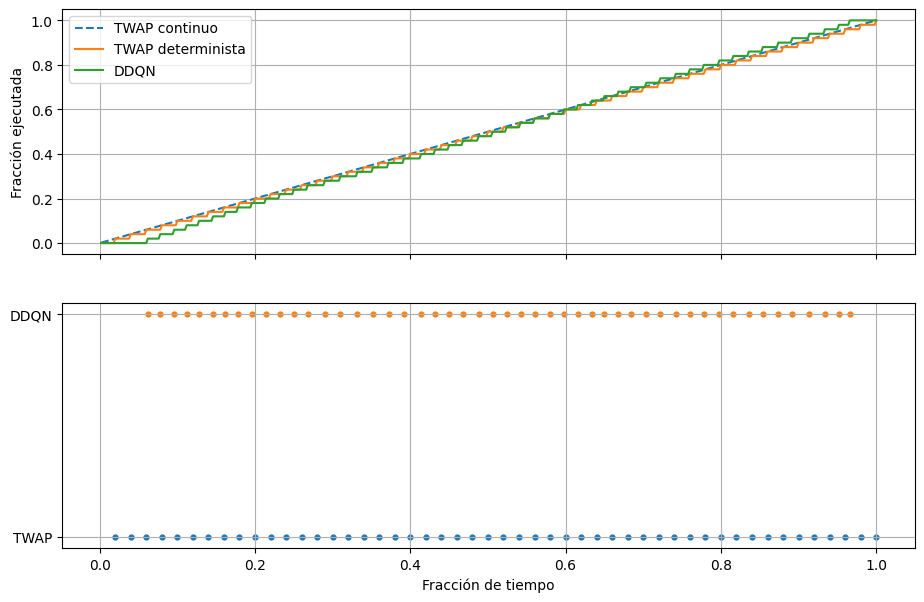

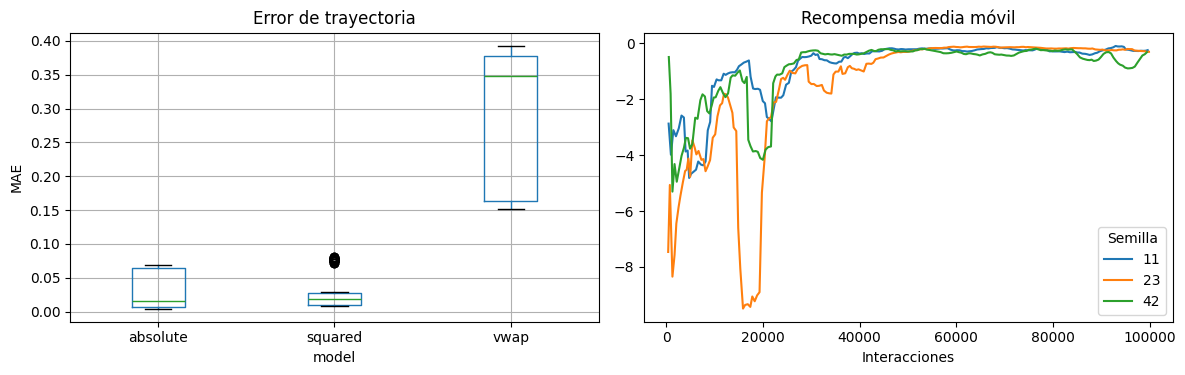

Objetivo de finalización alcanzado: True
Objetivo de error alcanzado: True
VWAP ejemplo: algoritmo 13.9552 mercado aproximado 13.95047647099097


In [7]:
case = cases[13]
model = models[(chosen, gamma_selected, SEEDS[0])]
ref, learned = evaluate(None, case), evaluate(model, case)
h = case[2]
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(np.arange(1, h+1)/h, np.arange(1, h+1)/h, '--', label='TWAP continuo')
axes[0].plot(np.arange(1, h+1)/h, ref['path'], label='TWAP determinista')
axes[0].plot(np.arange(1, h+1)/h, learned['path'], label='DDQN')
axes[0].set_ylabel('Fracción ejecutada'); axes[0].legend(); axes[0].grid()
for offset, (label, item) in enumerate((('TWAP', ref), ('DDQN', learned))):
    positions = np.flatnonzero(item['actions']) + 1
    axes[1].scatter(positions/h, np.full(len(positions), offset), label=label, s=12)
axes[1].set_yticks([0, 1], ['TWAP', 'DDQN']); axes[1].set_xlabel('Fracción de tiempo'); axes[1].grid()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
results[results.model != 'reference'].boxplot(column='mae', by='model', ax=axes[0])
axes[0].set_title('Error de trayectoria'); axes[0].set_ylabel('MAE')
for key, history in histories.items():
    if key[0] == chosen and key[1] == gamma_selected:
        axes[1].plot(history.step, history.reward.rolling(10, min_periods=1).mean(), label=str(key[2]))
axes[1].set_title('Recompensa media móvil'); axes[1].set_xlabel('Interacciones'); axes[1].legend(title='Semilla')
plt.suptitle(''); plt.tight_layout(); plt.show()
reference_median = results.loc[results.model == 'reference', 'mae'].median()
selected = results[(results.model == chosen) & (results.gamma == gamma_selected)]
print('Objetivo de finalización alcanzado:', selected.complete.mean() >= .9)
print('Objetivo de error alcanzado:', selected.mae.median() <= reference_median + .05)
print('VWAP ejemplo: algoritmo', learned['algo_vwap'], 'mercado aproximado', learned['market_vwap'])


## Interpretación de esta ejecución

Con las tres semillas y los 27 escenarios, la recompensa cuadrática con $\gamma=0{,}99$ completa las 81 órdenes y obtiene un error mediano de 0,0191; la referencia determinista obtiene 0,0090. El error máximo del agente es 0,0286. Cada semilla completa las 27 órdenes, aunque sus errores medianos varían entre 0,0092 y 0,0270. La curva individual ilustra el reparto, mientras que las tablas anteriores muestran los demás casos.

La recompensa absoluta con $\gamma=0{,}99$ completa un tercio de los casos. Con la cuadrática, elevar $\gamma$ a 0,999 también reduce la tasa de finalización a un tercio. Estas observaciones motivan la elección de la recompensa cuadrática y $\gamma=0{,}99$ para este experimento; no prueban que estos valores sean óptimos en general.

En el diagrama de cajas, la categoría `squared` reúne las dos configuraciones de $\gamma$; para compararlas por separado deben utilizarse las tablas. Las curvas de recompensa muestran la suma no descontada de recompensa por episodio, no el error TWAP. Los datos utilizados son históricos de REP, sin impacto de mercado ni costes, y la evaluación está dentro de `train`. Los días 12 de febrero y 1 de marzo de 2018 se excluyeron por descensos de `cumvol`. No se ha demostrado generalización fuera de muestra.
